# Figure 3: Observed and technical technology lifespans

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

In [51]:
# ---
# Lifespan parameters
# ---

# Observed retirement lifespans
expected_life = {
    "Bioenergy": 17,
    "Coal": 56,
    "Geothermal": 23,
    "Hydropower": 86,
    "Natural Gas": 44,
    "Nuclear": 31,
    "Oil": 41,
    "Solar PV": 8,
    "Wind Offshore": 22,
    "Wind Onshore": 15,
}

# Active fleet median ages
active_life = {
    "Bioenergy": 12,
    "Coal": 17,
    "Geothermal": 24,
    "Hydropower": 34,
    "Natural Gas": 17,
    "Nuclear": 39,
    "Oil": 18,
    "Solar PV": 5,
    "Wind Offshore": 5,
    "Wind Onshore": 8,
}


# ---
# Lifespan ranges
# ---

# Lower and upper technical lifespan estimates
technical_range = {
    "Bioenergy": (20, 45),
    "Coal": (20, 50),
    "Geothermal": (20, 100),
    "Hydropower": (30, 100),
    "Natural Gas": (30, 50),
    "Nuclear": (30, 80),
    "Oil": (20, 50),
    "Solar PV": (20, 35),
    "Wind Offshore": (25, 30),
    "Wind Onshore": (20, 40),
}

# Lower and upper retired lifespan estimates
observed_range = {
    "Bioenergy": (10, 47),
    "Coal": (46, 66),
    "Geothermal": (17, 30),
    "Hydropower": (34, 110),
    "Natural Gas": (25, 62),
    "Nuclear": (16, 45),
    "Oil": (20, 63),
    "Solar PV": (7, 13),
    "Wind Offshore": (18, 26),
    "Wind Onshore": (10, 24),
}

# Lower and upper active fleet age estimates
active_range = {
    "Bioenergy": (5, 41),
    "Coal": (9, 47),
    "Geothermal": (9, 46),
    "Hydropower": (12, 67),
    "Natural Gas": (8, 46),
    "Nuclear": (12, 49),
    "Oil": (8, 52),
    "Solar PV": (3, 11),
    "Wind Offshore": (3, 12),
    "Wind Onshore": (4, 17),
}
# ---
# Kaplan-Meier lifespan summary
# ---

# Add KM-derived estimates here without changing the original retired
# lifespan dictionaries above.
#
# Accepted structures:
#     {"lower": value}
#     {"lower": value, "mean": value}
#     {"lower": value, "mean": value, "upper": value}
#
# Existing "median" entries are also supported for backward compatibility.
# For the KM comparison and central plotting value, the preference is:
# mean -> median -> lower.
#
# Use np.nan for values that are not available. The plotting code will:
# - lower only: show an open marker with a right-pointing arrow;
# - lower + central value: show the lower error bar and a right-pointing arrow;
# - lower + central value + upper: show a complete two-sided error bar.
#
# Example only:
#     "Technology": {"lower": 25, "median": 40, "upper": 55}
#
# Populate these values directly from the KM analysis.
km_summary = {
    "Bioenergy": {"lower": 29, "median":68, "upper": np.nan},
    "Coal": {"lower": 52, "median": 61, "upper": np.nan},
    "Geothermal": {"lower": 23, "median": np.nan, "upper": np.nan},
    "Hydropower": {"lower": 117, "median": np.nan, "upper": np.nan},
    "Natural Gas": {"lower": 45, "median": 62, "upper": np.nan},
    "Nuclear": {"lower": 30, "median": 45, "upper": np.nan},
    "Oil": {"lower": 37, "median": 58, "upper": np.nan},
    "Solar PV": {"lower": 27, "median": 29, "upper": np.nan},
    "Wind Offshore": {"lower": 22, "median": 24, "upper": np.nan},
    "Wind Onshore": {"lower": 32, "median": 36, "upper": np.nan},
}



In [52]:
# ---
# Build summary dataframe
# ---

df = pd.DataFrame(
    {
        "Technology": expected_life.keys(),
        "Observed": expected_life.values(),
    }
)

# Technical lifespan bounds
df[["Lower", "Upper"]] = pd.DataFrame(
    df["Technology"].map(technical_range).tolist(),
    index=df.index,
)

# Technical lifespan midpoint
df["Mid"] = (
    df["Lower"] + df["Upper"]
) / 2

# Difference between observed and technical midpoint
df["Delta_yr"] = (
    df["Observed"] - df["Mid"]
)

df["Delta_pct"] = (
    100 * df["Delta_yr"] / df["Mid"]
).round().astype(int)


# KM preferred value for comparison with the technical midpoint.
# Preference: mean -> median -> lower.
def get_km_preferred_value(technology):
    values = km_summary.get(technology, {})

    for key in ["mean", "median", "lower"]:
        value = values.get(key, np.nan)

        if np.isfinite(value):
            return value, key

    return np.nan, "missing"


km_preferred = df["Technology"].apply(
    get_km_preferred_value
)

df["KM_Preferred"] = [
    value for value, _ in km_preferred
]

df["KM_Source"] = [
    source for _, source in km_preferred
]

# Percentage difference between the KM preferred value and
# the technical lifespan midpoint.
df["KM_Delta_yr"] = (
    df["KM_Preferred"] - df["Mid"]
)

df["KM_Delta_pct"] = (
    100 * df["KM_Delta_yr"] / df["Mid"]
).round()

# Final column order
df = df[
    [
        "Technology",
        "Observed",
        "Lower",
        "Mid",
        "Upper",
        "Delta_yr",
        "Delta_pct",
        "KM_Preferred",
        "KM_Source",
        "KM_Delta_yr",
        "KM_Delta_pct",
    ]
]

df

,Technology,Observed,Lower,Mid,Upper,Delta_yr,Delta_pct,KM_Preferred,KM_Source,KM_Delta_yr,KM_Delta_pct
0,Bioenergy,17,20,32.5,45,-15.5,-48,68,median,35.5,109.0
1,Coal,56,20,35.0,50,21.0,60,61,median,26.0,74.0
2,Geothermal,23,20,60.0,100,-37.0,-62,23,lower,-37.0,-62.0
3,Hydropower,86,30,65.0,100,21.0,32,117,lower,52.0,80.0
4,Natural Gas,44,30,40.0,50,4.0,10,62,median,22.0,55.0
5,Nuclear,31,30,55.0,80,-24.0,-44,45,median,-10.0,-18.0
6,Oil,41,20,35.0,50,6.0,17,58,median,23.0,66.0
7,Solar PV,8,20,27.5,35,-19.5,-71,29,median,1.5,5.0
8,Wind Offshore,22,25,27.5,30,-5.5,-20,24,median,-3.5,-13.0
9,Wind Onshore,15,20,30.0,40,-15.0,-50,36,median,6.0,20.0


In [53]:
# ---
# Style
# ---

FONT_MIN = 12.0
FONT_BASE = 12.0
FONT_TICKS = 12.0
FONT_TECH = 12.0
FONT_GROUP = 13.0
FONT_AXIS_LABEL = 13.5
FONT_DELTA = 9.5
FONT_LEGEND = 12.0

plt.rcParams.update(
    {
        "font.family": "Arial",
        "font.size": FONT_BASE,
        "axes.linewidth": 0.70,
        "axes.labelsize": FONT_AXIS_LABEL,
        "xtick.labelsize": FONT_TICKS,
        "ytick.labelsize": FONT_TECH,
        "legend.fontsize": FONT_LEGEND,
        "xtick.direction": "out",
        "ytick.direction": "out",
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "savefig.dpi": 600,
    }
)


# ---
# Palette
# ---

COLOR_TECH_RANGE = "#D9D9D9"
COLOR_RETIRED = "#B94745"
COLOR_ACTIVE_STAR = "#B8962E"
COLOR_GRID = "#BFBFBF"
COLOR_TEXT = 'black' #"#222222"
COLOR_SECONDARY_TEXT ='black' # "#555555"
COLOR_BACKGROUND = "white"
COLOR_GROUP_LINE = "#777777"
COLOR_KM = "#222222"

In [54]:
# ---
# Configuration
# ---

technology_col = "Technology"
analysis_year = 2025

# Small vertical offsets separate the four lifespan series within each technology.
TECHNICAL_Y_OFFSET = 0.00
OBSERVED_Y_OFFSET = -0.14
KM_Y_OFFSET = 0.13
ACTIVE_Y_OFFSET = 0.24
KM_ARROW_LENGTH = 8.0


# ---
# Technology groups
# ---

tech_groups = {
    "Fossil fuels": [
        "Coal",
        "Natural Gas",
        "Oil",
    ],
    "Core transition technologies": [
        "Solar PV",
        "Wind Onshore",
        "Wind Offshore",
        "Nuclear",
    ],
    "Other low-carbon technologies": [
        "Bioenergy",
        "Geothermal",
        "Hydropower",
    ],
}


# ---
# Prepare data
# ---

df_plot = df.copy()

# Ensure numeric columns
numeric_cols = [
    "Lower",
    "Upper",
    "Mid",
    "Observed",
    "Delta_pct",
    "KM_Preferred",
    "KM_Delta_pct",
]

for col in numeric_cols:
    if col in df_plot.columns:
        df_plot[col] = pd.to_numeric(
            df_plot[col],
            errors="coerce",
        )


# ---
# Order technologies within groups
# ---

# Order from older to younger according to observed retired median
ordered_groups = {}

for group_name, group_techs in tech_groups.items():
    subset_group = df_plot[
        df_plot[technology_col].isin(group_techs)
    ].copy()

    subset_group = subset_group.sort_values(
        by="Observed",
        ascending=False,
        na_position="last",
    )

    ordered_groups[group_name] = (
        subset_group[technology_col].tolist()
    )


# ---
# Build y positions
# ---

# Extra space is inserted between technology groups
TECH_SPACING = 1.00
GROUP_GAP = 0.75

y_positions = {}
group_header_positions = {}
group_line_positions = {}

current_y = 0.0

for group_name, techs in ordered_groups.items():
    if len(techs) == 0:
        continue

    first_y = current_y

    # Group heading sits above first technology
    group_header_positions[group_name] = (
        first_y - 0.68
    )

    # Thin horizontal line immediately above technologies
    group_line_positions[group_name] = (
        first_y - 0.43
    )

    for tech in techs:
        y_positions[tech] = current_y
        current_y += TECH_SPACING

    # Blank vertical space before next group
    current_y += GROUP_GAP


# ---
# Create ordered dataframe
# ---

ordered_techs = [
    tech
    for group_name in ordered_groups
    for tech in ordered_groups[group_name]
]

df_plot = (
    df_plot
    .set_index(technology_col)
    .loc[ordered_techs]
    .reset_index()
)

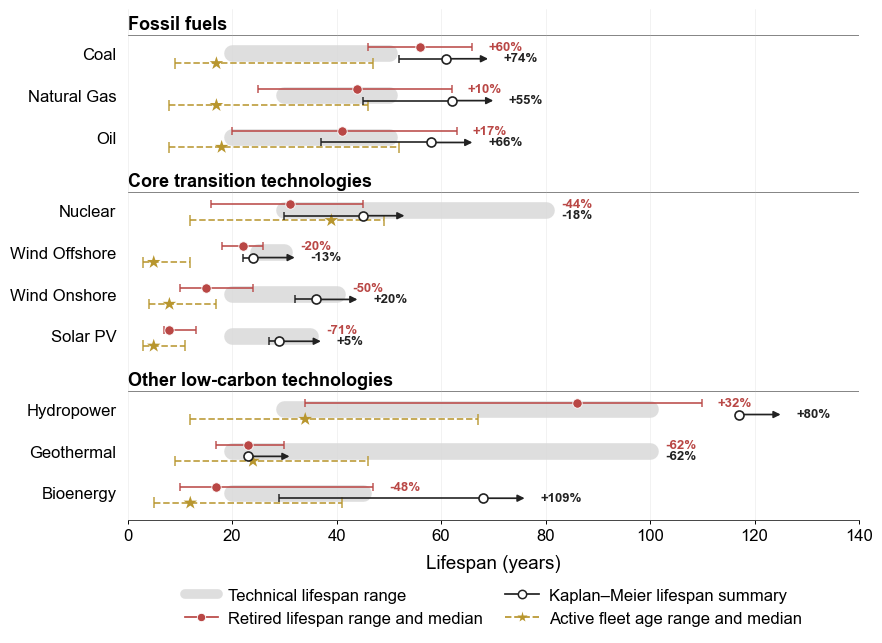

In [55]:
# ---
# Figure
# ---

fig, ax = plt.subplots(
    figsize=(9.2, 7.4),
)

fig.patch.set_facecolor(COLOR_BACKGROUND)
ax.set_facecolor(COLOR_BACKGROUND)


# ---
# Group headers and separator lines
# ---

for group_name in ordered_groups:
    if group_name not in group_header_positions:
        continue

    # Group heading
    # x is axes fraction, y is data coordinate
    ax.text(
        0.0,
        group_header_positions[group_name],
        group_name,
        transform=ax.get_yaxis_transform(),
        ha="left",
        va="center",
        fontsize=FONT_GROUP,
        fontweight="bold",
        color=COLOR_TEXT,
        clip_on=False,
    )

    # Thin separator
    ax.axhline(
        y=group_line_positions[group_name],
        xmin=0,
        xmax=1,
        color=COLOR_GROUP_LINE,
        linewidth=0.70,
        alpha=0.9,
        zorder=0,
    )


# ---
# Store label positions for axis limit
# ---

delta_label_positions = []
km_extent_positions = []


# ---
# Plot
# ---

for _, row in df_plot.iterrows():
    tech = row[technology_col]
    y = y_positions[tech]
    technical_y = y + TECHNICAL_Y_OFFSET
    observed_y = y + OBSERVED_Y_OFFSET
    active_y = y + ACTIVE_Y_OFFSET

    # Technical lifespan range
    if (
        np.isfinite(row["Lower"])
        and np.isfinite(row["Upper"])
    ):
        ax.plot(
            [
                row["Lower"],
                row["Upper"],
            ],
            [
                technical_y,
                technical_y,
            ],
            color=COLOR_TECH_RANGE,
            linewidth=12,
            alpha=0.85,
            solid_capstyle="round",
            zorder=1,
        )

    # Retired lifespan series: fixed red for a simpler visual encoding.
    obs_color = COLOR_RETIRED

    # Observed / retired lifespan range
    obs_high_for_label = (
        row["Observed"]
        if np.isfinite(row["Observed"])
        else 0
    )

    if (
        tech in observed_range
        and np.isfinite(row["Observed"])
    ):
        obs_low, obs_high = observed_range[tech]

        if (
            np.isfinite(obs_low)
            and np.isfinite(obs_high)
        ):
            obs_high_for_label = obs_high

            lower_error = row["Observed"] - obs_low
            upper_error = obs_high - row["Observed"]

            # Prevent negative error bars
            lower_error = max(
                lower_error,
                0,
            )
            upper_error = max(
                upper_error,
                0,
            )

            ax.errorbar(
                row["Observed"],
                observed_y,
                xerr=np.array(
                    [
                        [lower_error],
                        [upper_error],
                    ]
                ),
                fmt="none",
                ecolor=obs_color,
                elinewidth=1.25,
                capsize=3.2,
                capthick=1.1,
                alpha=0.90,
                zorder=3,
            )

    # Observed / retired median
    if np.isfinite(row["Observed"]):
        ax.scatter(
            row["Observed"],
            observed_y,
            s=46,
            color=obs_color,
            edgecolor="white",
            linewidth=0.6,
            zorder=4,
        )

    # Kaplan-Meier lifespan summary (additional series)
    km_values = km_summary.get(tech, {})
    km_low = km_values.get("lower", np.nan)
    km_mean = km_values.get("mean", np.nan)
    km_median = km_values.get("median", np.nan)
    km_high = km_values.get("upper", np.nan)
    km_y = y + KM_Y_OFFSET

    # Preferred KM central estimate for plotting:
    # mean -> median -> lower.
    if np.isfinite(km_mean):
        km_center = km_mean
    elif np.isfinite(km_median):
        km_center = km_median
    else:
        km_center = np.nan

    km_extent_for_label = (
        km_center
        if np.isfinite(km_center)
        else (km_low if np.isfinite(km_low) else 0)
    )

    # Complete KM summary: lower + median + upper
    if (
        np.isfinite(km_low)
        and np.isfinite(km_center)
        and np.isfinite(km_high)
    ):
        km_lower_error = max(km_center - km_low, 0)
        km_upper_error = max(km_high - km_center, 0)

        ax.errorbar(
            km_center,
            km_y,
            xerr=np.array(
                [
                    [km_lower_error],
                    [km_upper_error],
                ]
            ),
            fmt="none",
            ecolor=COLOR_KM,
            elinewidth=1.25,
            capsize=3.2,
            capthick=1.1,
            alpha=0.95,
            zorder=6,
        )

        ax.scatter(
            km_center,
            km_y,
            s=42,
            facecolor=COLOR_BACKGROUND,
            edgecolor=COLOR_KM,
            linewidth=1.2,
            zorder=7,
        )

        km_extent_positions.append(km_high)
        km_extent_for_label = km_high

    # Partial KM summary: lower + median, upper bound open
    elif (
        np.isfinite(km_low)
        and np.isfinite(km_center)
    ):
        km_lower_error = max(km_center - km_low, 0)

        ax.errorbar(
            km_center,
            km_y,
            xerr=np.array(
                [
                    [km_lower_error],
                    [0],
                ]
            ),
            fmt="none",
            ecolor=COLOR_KM,
            elinewidth=1.25,
            capsize=3.2,
            capthick=1.1,
            alpha=0.95,
            zorder=6,
        )

        ax.scatter(
            km_center,
            km_y,
            s=42,
            facecolor=COLOR_BACKGROUND,
            edgecolor=COLOR_KM,
            linewidth=1.2,
            zorder=7,
        )

        km_arrow_end = km_center + KM_ARROW_LENGTH

        ax.annotate(
            "",
            xy=(km_arrow_end, km_y),
            xytext=(km_center, km_y),
            arrowprops={
                "arrowstyle": "-|>",
                "lw": 1.25,
                "color": COLOR_KM,
                "shrinkA": 0,
                "shrinkB": 0,
                "mutation_scale": 10,
            },
            zorder=6,
        )

        km_extent_positions.append(km_arrow_end)
        km_extent_for_label = km_arrow_end

    # Lower KM bound only: open marker and open upper direction
    elif np.isfinite(km_low):
        ax.scatter(
            km_low,
            km_y,
            s=42,
            facecolor=COLOR_BACKGROUND,
            edgecolor=COLOR_KM,
            linewidth=1.2,
            zorder=7,
        )

        km_arrow_end = km_low + KM_ARROW_LENGTH

        ax.annotate(
            "",
            xy=(km_arrow_end, km_y),
            xytext=(km_low, km_y),
            arrowprops={
                "arrowstyle": "-|>",
                "lw": 1.25,
                "color": COLOR_KM,
                "shrinkA": 0,
                "shrinkB": 0,
                "mutation_scale": 10,
            },
            zorder=6,
        )

        km_extent_positions.append(km_arrow_end)
        km_extent_for_label = km_arrow_end

    # Active fleet age range
    active_high_for_label = (
        active_life[tech]
        if (
            tech in active_life
            and np.isfinite(active_life[tech])
        )
        else 0
    )

    if tech in active_range:
        active_low, active_high = active_range[tech]

        if (
            np.isfinite(active_low)
            and np.isfinite(active_high)
        ):
            active_high_for_label = active_high
            cap_half_height = 0.13

            # Horizontal dashed range
            ax.hlines(
                y=active_y,
                xmin=active_low,
                xmax=active_high,
                color=COLOR_ACTIVE_STAR,
                linewidth=1.25,
                linestyles="--",
                alpha=0.90,
                zorder=3.5,
            )

            # End caps
            ax.vlines(
                x=[
                    active_low,
                    active_high,
                ],
                ymin=active_y - cap_half_height,
                ymax=active_y + cap_half_height,
                color=COLOR_ACTIVE_STAR,
                linewidth=1.1,
                alpha=0.90,
                zorder=3.5,
            )

    # Active fleet median age
    if (
        tech in active_life
        and np.isfinite(active_life[tech])
    ):
        ax.scatter(
            active_life[tech],
            active_y,
            marker="*",
            s=105,
            facecolor=COLOR_ACTIVE_STAR,
            edgecolor="none",
            zorder=5,
        )

    # Percentage differences relative to the technical midpoint
    # Red: retired median vs technical midpoint.
    # Black: KM preferred value vs technical midpoint.
    retired_label_anchor = max(
        (
            row["Upper"]
            if np.isfinite(row["Upper"])
            else 0
        ),
        (
            obs_high_for_label
            if np.isfinite(obs_high_for_label)
            else 0
        ),
    )

    km_label_anchor = max(
        (
            row["Upper"]
            if np.isfinite(row["Upper"])
            else 0
        ),
        (
            km_extent_for_label
            if np.isfinite(km_extent_for_label)
            else 0
        ),
    )

    label_offset = 3.0
    retired_label_x = retired_label_anchor + label_offset
    km_label_x = km_label_anchor + label_offset

    if np.isfinite(row["Delta_pct"]):
        ax.text(
            retired_label_x,
            observed_y,
            f'{row["Delta_pct"]:+.0f}%',
            va="center",
            ha="left",
            fontsize=FONT_DELTA,
            fontweight="bold",
            color=COLOR_RETIRED,
            zorder=8,
        )

    if np.isfinite(row["KM_Delta_pct"]):
        ax.text(
            km_label_x,
            km_y,
            f'{row["KM_Delta_pct"]:+.0f}%',
            va="center",
            ha="left",
            fontsize=FONT_DELTA,
            fontweight="bold",
            color=COLOR_KM,
            zorder=8,
        )

    delta_label_positions.extend(
        [
            retired_label_x + 9,
            km_label_x + 9,
        ]
    )

# ---
# Y axis
# ---

yticks = [
    y_positions[tech]
    for tech in ordered_techs
]

ax.set_yticks(yticks)

ax.set_yticklabels(
    ordered_techs,
    fontsize=FONT_TECH,
    fontweight="normal",
    color=COLOR_TEXT,
)


# ---
# X axis label
# ---

ax.set_xlabel(
    "Lifespan (years)",
    fontsize=FONT_AXIS_LABEL,
    fontweight="normal",
    color=COLOR_TEXT,
    labelpad=8,
)


# ---
# X axis limit
# ---

xmax_candidates = []

# Technical range
technical_upper = pd.to_numeric(
    df_plot["Upper"],
    errors="coerce",
).dropna()

if len(technical_upper) > 0:
    xmax_candidates.append(
        technical_upper.max(),
    )

# Observed ranges
for tech in ordered_techs:
    if tech in observed_range:
        _, obs_high = observed_range[tech]

        if np.isfinite(obs_high):
            xmax_candidates.append(
                obs_high,
            )

# KM summaries
for tech in ordered_techs:
    km_values = km_summary.get(tech, {})

    for key in [
        "lower",
        "mean",
        "median",
        "upper",
    ]:
        km_value = km_values.get(key, np.nan)

        if np.isfinite(km_value):
            xmax_candidates.append(km_value)

if len(km_extent_positions) > 0:
    xmax_candidates.append(
        max(km_extent_positions),
    )

# Active ranges
for tech in ordered_techs:
    if tech in active_range:
        _, active_high = active_range[tech]

        if np.isfinite(active_high):
            xmax_candidates.append(
                active_high,
            )

# Active medians
for tech in ordered_techs:
    if (
        tech in active_life
        and np.isfinite(active_life[tech])
    ):
        xmax_candidates.append(
            active_life[tech],
        )

# Delta labels
if len(delta_label_positions) > 0:
    xmax_candidates.append(
        max(delta_label_positions),
    )

xmax = max(xmax_candidates)

# Round to nearest useful interval
xmax = np.ceil(xmax / 10) * 10

ax.set_xlim(
    0,
    xmax,
)


# ---
# Y limits
# ---

last_y = max(
    y_positions.values(),
)

ax.set_ylim(
    last_y + 0.65,
    -1.05,
)


# ---
# Grid
# ---

ax.grid(
    axis="x",
    color=COLOR_GRID,
    linewidth=0.45,
    linestyle="-",
    alpha=0.30,
    zorder=0,
)

ax.grid(
    axis="y",
    visible=False,
)

ax.set_axisbelow(True)


# ---
# Spines
# ---

for spine in [
    "top",
    "right",
    "left",
]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#444444")
ax.spines["bottom"].set_linewidth(0.70)


# ---
# Ticks
# ---

ax.tick_params(
    axis="y",
    length=0,
    pad=8,
    colors=COLOR_TEXT,
    labelsize=FONT_TECH,
)

ax.tick_params(
    axis="x",
    direction="out",
    length=3.0,
    width=0.70,
    pad=3,
    colors=COLOR_TEXT,
    labelsize=FONT_TICKS,
)


# ---
# Legend
# ---

legend_elements = [
    Line2D(
        [0],
        [0],
        color=COLOR_TECH_RANGE,
        lw=7,
        solid_capstyle="round",
        alpha=0.85,
        label="Technical lifespan range",
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_RETIRED,
        lw=1.25,
        marker="o",
        markerfacecolor=COLOR_RETIRED,
        markeredgecolor="white",
        markeredgewidth=0.6,
        markersize=6,
        label="Retired lifespan range and median",
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_KM,
        lw=1.25,
        marker="o",
        markerfacecolor=COLOR_BACKGROUND,
        markeredgecolor=COLOR_KM,
        markeredgewidth=1.1,
        markersize=6,
        label="Kaplan–Meier lifespan summary",
    ),
    Line2D(
        [0],
        [0],
        color=COLOR_ACTIVE_STAR,
        lw=1.25,
        linestyle="--",
        marker="*",
        markerfacecolor=COLOR_ACTIVE_STAR,
        markeredgecolor="none",
        markersize=8,
        label="Active fleet age range and median",
    ),
]

ax.legend(
    handles=legend_elements,
    frameon=False,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        -0.12,
    ),
    ncol=2,
    fontsize=FONT_LEGEND,
    columnspacing=1.35,
    handlelength=2.0,
    handletextpad=0.6,
    borderaxespad=0,
)


# ---
# Layout
# ---

fig.subplots_adjust(
    left=0.20,
    right=0.995,
    top=0.98,
    bottom=0.29,
)


# ---
# Save
# ---

plt.savefig(
    "figures/main/figure-3.png",
    dpi=600,
    bbox_inches="tight",
    transparent=True,
)

plt.savefig(
    "figures/main/figure-3.pdf",
    bbox_inches="tight",
    transparent=True,
)

plt.show()